<div align="center" style="font-family:Georgia, serif; color:red;">

<strong style="font-size: 20px;">Escuela Politécnica Nacional</strong><br>
<strong style="font-size: 20px;">Facultad de Ingenieria de Sistemas</strong><br>
<strong style="font-size: 20px;"></strong>

</div>

-----------------

<p style="font-family:Georgia, serif;">
  <strong style="color:red;">Nombre:</strong> 
  <span>Dany Molina</span>
</p>


<p style= "font-family:Georgia, serif;">
  <strong style = "color:red;">Fecha:</strong> 
  <span>24/10/2026</span>
</p>

<div style="text-align: center; font-family:Georgia, serif; margin-top: 20px;">

<h4><strong>Búsqueda Booleana

 </strong></h4>

</div>


# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [ ]:
#%pip install nltk

import re
import time
import statistics
import nltk
from nltk.corpus import gutenberg

# Descargar el corpus
nltk.download('gutenberg', quiet=True)

nombres_archivos = gutenberg.fileids()

documentos = {
    nombre: gutenberg.raw(nombre)
    for nombre in nombres_archivos
}
print("\n------------------------------------------------------")
print("Cantidad de documentos en el corpus:", len(documentos))
print("------------------------------------------------------\n")
#Tamaño de cada documento
print("--------------------------------------------------------")
print("Tamaño de cada documento (en caracteres y palabras)")
print("--------------------------------------------------------\n")
for identificador, texto in documentos.items():
    print(identificador, "| Caracteres: ", len(texto),"| Palabras sepradas por espacios: ",len(texto.split()))


#Configuración consistenete de procesamiento
def tokenizar(texto):
    texto= texto.lower()
    return re.findall(r"\w+",texto, flags=re.UNICODE)

#Prepara los tokens fuera del tiempo de consulta
documentos_tokenizados = {
    identificador: tokenizar(texto)
    for identificador, texto in documentos.items()
}

total_tokens = sum(
    len(tokens)
    for tokens in documentos_tokenizados.values()
)

print("\nTotal de tokens: ", total_tokens)
print("Tamaño del vocabulario: ",len({
    token
    for tokens in documentos_tokenizados.values()
    for token in tokens
}))



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.

------------------------------------------------------
Cantidad de documentos en el corpus: 18
------------------------------------------------------

--------------------------------------------------------
Tamaño de cada documento (en caracteres y palabras)
--------------------------------------------------------

austen-emma.txt | Caracteres:  887071 | Palabras sepradas por espacios:  158167
austen-persuasion.txt | Caracteres:  466292 | Palabras sepradas por espacios:  83308
austen-sense.txt | Caracteres:  673022 | Palabras sepradas por espacios:  118675
bible-kjv.txt | Caracteres:  4332554 | Palabras sepradas por espacios:  821133
blake-poems.txt | Caracteres:  38153 | Palabras sepradas por espacios:  6845
bryant-stories.txt | Caracteres:  249439 | Palabras sepradas por espacios:  45988
burgess-busterbrown.txt | Caracteres:  84663 | Palabras sepradas por espacios:  15870
carroll-alice.txt | Caracteres:  144395 | Pal

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [14]:
def buscar_secuencial(consulta, documentos_tokenizados):
    #Normalizar el término consultado
    tokens_consulta = tokenizar(consulta)
    if len(tokens_consulta) !=1:
        return []
    termino = tokens_consulta[0]
    resultados = []
    #Primer for: recorre los documentos
    for identificador, tokens in documentos_tokenizados.items():
        #Segundo for: recorre los tokens del documento
        for token in tokens:
            if token == termino:
                resultados.append(identificador)
                break
    return resultados

#Probar términos frecuentes, poco frecuentes e inexistentes
consultas=["the", "whale","xyznofound123"]

for consulta in consultas:
    encontrados = buscar_secuencial(
        consulta,
        documentos_tokenizados
    )
    print(f"Consulta: {consulta!r}")
    print("Documentos econtrados: ",encontrados)
    print("Cantidad: ", len(encontrados))
    print("-"*50)

Consulta: 'the'
Documentos econtrados:  ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Cantidad:  18
--------------------------------------------------
Consulta: 'whale'
Documentos econtrados:  ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
Cantidad:  6
--------------------------------------------------
Consulta: 'xyznofound123'
Documentos econtrados:  []
Cantidad:  0
--------------------------------------------------


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [20]:
def medir_busqueda(funcion, consulta, datos, repeticiones=30):
    tiempos_ms=[]

    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        
        funcion(consulta,datos)

        fin = time.perf_counter_ns()

        tiempo_ms = (fin - inicio)/ 1_000_000
        tiempos_ms.append(tiempo_ms)
    return statistics.mean(tiempos_ms)

consultas = ["the", "whale", "tiempo"]

for consulta in consultas:
    promedio = medir_busqueda(
        buscar_secuencial,
        consulta,
        documentos_tokenizados,
        repeticiones=30
    )

    print (
        f"consulta: {consulta!r} |"
        f"Promedio: {promedio:.6f} ms"
        )


consulta: 'the' |Promedio: 0.012697 ms
consulta: 'whale' |Promedio: 45.991770 ms
consulta: 'tiempo' |Promedio: 58.253083 ms


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [24]:
#Construcción del índice invertido
indice_invertido ={}

for identificador, tokens in documentos_tokenizados.items():
    for termino in set(tokens):
        if termino not in indice_invertido:
            indice_invertido[termino]= set()
        indice_invertido[termino].add(identificador)

print("Tamaño del vocabulario: ",len(indice_invertido))
print("Ejemplo de términos del índice: ")

for termino in list (indice_invertido.keys())[:10]:
    print(termino,"->", sorted(indice_invertido[termino]))


#terminos de postings y cálculo de DF
terminos =["the", "whale", "tiempo", "xyznotfound123"]

for termino in terminos:
    postings = indice_invertido.get(termino,set())
    df = len(postings)

    print("Término: ",termino)
    print("Postings: ",sorted(postings))
    print("DF: ", df)
    print("-"*50)

#Consultar de un término
def buscar_con_indice(consulta, indice):
    tokens_consulta = tokenizar(consulta)

    if len(tokens_consulta)!=1:
        return set()

    termino = tokens_consulta[0]
    return indice.get(termino,set())

#Prueba de consultas de un termino
consultas = ["the", "whale", "tiempo", "xyznotfound123"]

for consulta in consultas:
    resultados = buscar_con_indice(consulta,indice_invertido)

    print("Consulta: ",consulta)
    print("Documentos encontrados:", sorted(resultados))
    print("Cantidad:", len(resultados))
    print("-" * 50)

#Consultas booleanas
#Universo de documentos de la colección 
universo_documentos = set(documentos_tokenizados.keys())

#Operador AND: documentos que contiene ambos terminos
def buscar_and(termino1,termino2, indice):
    resultados1 = buscar_con_indice(termino1,indice)
    resultados2 = buscar_con_indice(termino2,indice)

    return resultados1 & resultados2

#Operador OR: docuemntos que contienen al menos uno de los términos
def buscar_or(termino1,termino2,indice):
    resultados1 = buscar_con_indice(termino1,indice)
    resultados2 = buscar_con_indice(termino2,indice)
    
    return resultados1 | resultados2 

#Operador NOT: documentos que no contienen el término
def buscar_not(termino1,indice,universo):
    resultados = buscar_con_indice(termino,indice)

    return universo-resultados

# Consulta AND
resultado_and = buscar_and("whale", "sea", indice_invertido)
print("whale AND sea:", sorted(resultado_and))
print("Cantidad:", len(resultado_and))
print("-" * 50)

# Consulta OR
resultado_or = buscar_or("whale", "sea", indice_invertido)
print("whale OR sea:", sorted(resultado_or))
print("Cantidad:", len(resultado_or))
print("-" * 50)

# Consulta NOT
resultado_not = buscar_not(
    "whale",
    indice_invertido,
    universo_documentos
)
print("NOT whale:", sorted(resultado_not))
print("Cantidad:", len(resultado_not))
    


Tamaño del vocabulario:  42099
Ejemplo de términos del índice: 
liveliest -> ['austen-emma.txt', 'milton-paradise.txt']
insignificance -> ['austen-emma.txt', 'austen-sense.txt', 'chesterton-brown.txt']
prize -> ['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'carroll-alice.txt', 'chesterton-brown.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
seemingly -> ['austen-emma.txt', 'austen-persuasion.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt']
shakespeare -> ['austen-emma.txt', 'austen-sense.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'melville-moby_dick.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt']
acquittal -> ['austen-emma.txt', 'austen-persuasion.txt']
mercantile -> ['austen-emma.txt', 'whitman-leaves.txt']
wicked -> ['austen-emma.txt', 'auste

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [25]:

# Etapa 5: Comparación entre búsqueda secuencial e índice invertido

consultas = ["the", "whale", "tiempo", "xyznotfound123"]
repeticiones = 30

resultados_comparacion = []

for consulta in consultas:
    # Obtener resultados de ambos métodos
    resultado_secuencial = set(
        buscar_secuencial(consulta, documentos_tokenizados)
    )

    resultado_indice = buscar_con_indice(
        consulta, indice_invertido
    )

    # Comprobar que ambos métodos devuelven los mismos documentos
    coinciden = resultado_secuencial == resultado_indice

    # Medir el tiempo promedio de 30 ejecuciones
    tiempo_secuencial = medir_busqueda(
        buscar_secuencial,
        consulta,
        documentos_tokenizados,
        repeticiones
    )

    tiempo_indice = medir_busqueda(
        buscar_con_indice,
        consulta,
        indice_invertido,
        repeticiones
    )

    resultados_comparacion.append({
        "consulta": consulta,
        "coinciden": coinciden,
        "cantidad_documentos": len(resultado_secuencial),
        "tiempo_secuencial_ms": tiempo_secuencial,
        "tiempo_indice_ms": tiempo_indice
    })

    print("=" * 60)
    print("Consulta:", consulta)
    print("¿Coinciden los resultados?:", coinciden)
    print("Documentos encontrados:", len(resultado_secuencial))
    print("IDs búsqueda secuencial:", sorted(resultado_secuencial))
    print("IDs índice invertido:", sorted(resultado_indice))
    print(f"Tiempo secuencial: {tiempo_secuencial:.6f} ms")
    print(f"Tiempo índice invertido: {tiempo_indice:.6f} ms")

# Tabla resumen
import pandas as pd

tabla_comparacion = pd.DataFrame(resultados_comparacion)
display(tabla_comparacion)


Consulta: the
¿Coinciden los resultados?: True
Documentos encontrados: 18
IDs búsqueda secuencial: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
IDs índice invertido: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Tiempo secuencial: 0.010890 ms
Tiempo í

,consulta,coinciden,cantidad_documentos,tiempo_secuencial_ms,tiempo_indice_ms
0,the,True,18,0.010890,0.003973
1,whale,True,6,35.839343,0.002367
2,tiempo,True,0,58.286240,0.002247
3,xyznotfound123,True,0,57.388460,0.002417


### Conclusión

Se compararon los métodos de búsqueda secuencial y de índice invertido mediante cuatro consultas: the, whale, tiempo y xyznotfound123. Los resultados demostraron que ambos métodos recuperaron exactamente los mismos identificadores de documentos en todas las consultas, obteniendo una coincidencia del 100%.

En la consulta **the**, ambos métodos encontradron los 18 documentos de la colección, con tiempos promedios de 0.010890 ms para lbúsqueda secuencial y 0.003973 ms para el índice invertido. Para **whale**, se encontraron seis documentos; sin embargo, el invertido tardó 0.002367 ms. Por otro parte, las consultas tiempo y xyznotfound123 no encontraron documentos, y sus tiempos secuenciales fueron de 58.286240 ms y 57.388460 ms, respectivamente frente a aproximadamente 0.002 ms para el índice inevertido.

Por lo tanto, el índice invertido presentó un mejor rendimiento en las cuatro consultas evaluadas, manteniendo la misma exactitud que la búsqueda secuencial. Esto evidencia la ventaja de almacenar previamente las asociacionesentre términosy documentos, ya que permite recuperar los resultados sin recorrer todods los tokens de la colección durante cada consulta. La diferencia en las que el método secuencial tuvo que revisar toda la colección.

### Parte B. Corpus grande

**6. Descarga de Gutenberg**

El corpus ya está extraído en `Corpus\cache`.

La siguiente celda verifica los archivos TXT extraídos y cuenta los documentos válidos sin leer el TAR.

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [1]:

from pathlib import Path
import re

CARPETA_CORPUS_EXTRAIDO = Path.cwd() / "Corpus" / "cache"
print("Corpus extraído encontrado:", CARPETA_CORPUS_EXTRAIDO.exists())
print("Ruta:", CARPETA_CORPUS_EXTRAIDO)

if CARPETA_CORPUS_EXTRAIDO.exists():
    archivos_txt = list(CARPETA_CORPUS_EXTRAIDO.rglob("*.txt"))
    identificadores = set()
    for archivo in archivos_txt:
        nombre = archivo.stem.lower()
        coincidencia = re.fullmatch(r"(?:pg)?(\\d+)(?:[-_]\\d+)*", nombre)
        identificadores.add("gutenberg_" + coincidencia.group(1) if coincidencia else nombre)
    print("Archivos TXT encontrados:", len(archivos_txt))
    print("Documentos válidos únicos:", len(identificadores))
else:
    print("Verifica que el corpus fue extraído en Corpus/cache.")


Corpus extraído encontrado: True
Ruta: c:\Users\HP VICTUS\Documents\Recuperacion de la Informacion\Revision Machine Learning\Corpus\cache
Archivos TXT encontrados: 78145
Documentos válidos únicos: 78145


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [2]:
from pathlib import Path
import re
import time
import statistics
import tracemalloc
import gc
import pandas as pd

CARPETA_CORPUS = Path.cwd() / "Corpus" / "cache"
CARPETA_EXTRAIDA = CARPETA_CORPUS

if not CARPETA_EXTRAIDA.exists():
    raise FileNotFoundError(f"No se encontró el corpus extraído: {CARPETA_EXTRAIDA}")

TAMANIOS_SUBCONJUNTOS = [50, 100, 250, 500, 1000]
CONSULTAS = ["the", "whale", "tiempo", "xyznotfound123"]
REPETICIONES = 5


def obtener_id_canonico(ruta):
    nombre = Path(ruta).stem.lower()
    coinc = re.fullmatch(r"(?:pg)?(\d+)(?:[-_]\d+)*", nombre)
    return "gutenberg_" + coinc.group(1) if coinc else nombre


def listar_documentos_gutenberg():
    documentos = {}
    for ruta in CARPETA_EXTRAIDA.rglob("*"):
        if ruta.is_file() and ruta.suffix.lower() == ".txt":
            documentos.setdefault(obtener_id_canonico(ruta.name), ruta)
    return [documentos[k] for k in sorted(documentos, key=str.lower)]


archivos_unicos = listar_documentos_gutenberg()
print("Documentos válidos y únicos encontrados:", len(archivos_unicos))


def leer_documento(referencia):
    return Path(referencia).read_text(encoding="utf-8", errors="ignore")


def tokenizar(texto):
    return re.findall(r"\w+", texto.lower(), flags=re.UNICODE)


def buscar_secuencial(consulta, documentos_tokenizados):
    tokens = tokenizar(consulta)
    if len(tokens) != 1:
        return set()
    termino = tokens[0]
    return {doc for doc, palabras in documentos_tokenizados.items()
            if termino in palabras}


def construir_indice_invertido(documentos_tokenizados):
    indice = {}
    for doc, tokens in documentos_tokenizados.items():
        for termino in set(tokens):
            indice.setdefault(termino, set()).add(doc)
    return indice


def buscar_con_indice(consulta, indice):
    tokens = tokenizar(consulta)
    if len(tokens) != 1:
        return set()
    return indice.get(tokens[0], set()).copy()


def medir_busqueda(funcion, consulta, datos, repeticiones=5):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        funcion(consulta, datos)
        tiempos.append((time.perf_counter_ns() - inicio) / 1_000_000)
    return statistics.mean(tiempos)


if not archivos_unicos:
    raise ValueError("No se encontraron archivos TXT dentro del corpus.")

TAMANIOS_VALIDOS = sorted(set(min(n, len(archivos_unicos))
                              for n in TAMANIOS_SUBCONJUNTOS if n > 0))
resultados_experimento = []
resultados_consultas = []

for tamano in TAMANIOS_VALIDOS:
    print("\n" + "=" * 65)
    print(f"SUBCONJUNTO: {tamano} DOCUMENTOS")
    gc.collect()
    tracemalloc.start()
    tracemalloc.reset_peak()

    inicio = time.perf_counter()
    documentos_tokenizados = {}
    for referencia in archivos_unicos[:tamano]:
        doc = obtener_id_canonico(referencia)
        documentos_tokenizados[doc] = tokenizar(leer_documento(referencia))
    tiempo_procesamiento = (time.perf_counter() - inicio) * 1000
    numero_tokens = sum(len(tokens) for tokens in documentos_tokenizados.values())

    tiempos_secuenciales = {q: medir_busqueda(buscar_secuencial, q,
                                               documentos_tokenizados, REPETICIONES)
                            for q in CONSULTAS}
    inicio = time.perf_counter()
    indice_invertido = construir_indice_invertido(documentos_tokenizados)
    tiempo_indice = (time.perf_counter() - inicio) * 1000

    resultados_correctos = {}
    for consulta in CONSULTAS:
        secuencial = buscar_secuencial(consulta, documentos_tokenizados)
        indexado = buscar_con_indice(consulta, indice_invertido)
        tiempo_indexado = medir_busqueda(buscar_con_indice, consulta,
                                         indice_invertido, REPETICIONES)
        resultados_correctos[consulta] = secuencial == indexado
        resultados_consultas.append({
            "Documentos": len(documentos_tokenizados), "Consulta": consulta,
            "Coincidencias": len(secuencial),
            "Resultados iguales": resultados_correctos[consulta],
            "Secuencial (ms)": tiempos_secuenciales[consulta],
            "Índice (ms)": tiempo_indexado,
            "Aceleración (x)": (tiempos_secuenciales[consulta] / tiempo_indexado
                                 if tiempo_indexado else None) })
        print(f"{consulta!r}: {len(secuencial)} resultados, igual={resultados_correctos[consulta]}, "
              f"secuencial={tiempos_secuenciales[consulta]:.6f} ms, índice={tiempo_indexado:.6f} ms")

    memoria_actual, memoria_pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    resultados_experimento.append({
        "Documentos": len(documentos_tokenizados), "Tokens": numero_tokens,
        "Términos únicos del índice": len(indice_invertido),
        "Procesamiento (ms)": tiempo_procesamiento,
        "Construcción índice (ms)": tiempo_indice,
        "Memoria actual trazada (MB)": memoria_actual / 1024**2,
        "Memoria pico trazada (MB)": memoria_pico / 1024**2,
        "Todas las consultas coinciden": all(resultados_correctos.values()) })
    del documentos_tokenizados, indice_invertido
    gc.collect()

df_experimento = pd.DataFrame(resultados_experimento)
df_consultas = pd.DataFrame(resultados_consultas)
print("\nTABLA 1: RECURSOS Y PROCESAMIENTO")
display(df_experimento.round(4))
print("\nTABLA 2: COMPARACIÓN DE BÚSQUEDAS")
display(df_consultas.round(6))
print("\nVERIFICACIÓN CORRECTA." if df_consultas["Resultados iguales"].all()
      else "\nADVERTENCIA: existen diferencias entre métodos.")


Documentos válidos y únicos encontrados: 78145

SUBCONJUNTO: 50 DOCUMENTOS
'the': 50 resultados, igual=True, secuencial=0.024540 ms, índice=0.009980 ms
'whale': 9 resultados, igual=True, secuencial=42.955900 ms, índice=0.008820 ms
'tiempo': 0 resultados, igual=True, secuencial=68.182700 ms, índice=0.008100 ms
'xyznotfound123': 0 resultados, igual=True, secuencial=62.445220 ms, índice=0.014440 ms

SUBCONJUNTO: 100 DOCUMENTOS
'the': 100 resultados, igual=True, secuencial=0.049020 ms, índice=0.012440 ms
'whale': 14 resultados, igual=True, secuencial=104.635880 ms, índice=0.009340 ms
'tiempo': 2 resultados, igual=True, secuencial=118.546220 ms, índice=0.008640 ms
'xyznotfound123': 0 resultados, igual=True, secuencial=120.249320 ms, índice=0.012540 ms

SUBCONJUNTO: 250 DOCUMENTOS
'the': 250 resultados, igual=True, secuencial=0.113440 ms, índice=0.012400 ms
'whale': 40 resultados, igual=True, secuencial=291.992240 ms, índice=0.015500 ms
'tiempo': 3 resultados, igual=True, secuencial=318.0017

,Documentos,Tokens,Términos únicos del índice,Procesamiento (ms),Construcción índice (ms),Memoria actual trazada (MB),Memoria pico trazada (MB),Todas las consultas coinciden
0,50,4192695,76173,7803.1068,910.4002,235.5708,236.0677,True
1,100,7450460,123522,18049.3559,2245.0941,426.0039,426.4993,True
2,250,19418127,323228,48031.0334,6342.7583,1114.2226,1114.7156,True
3,500,36539414,427975,106298.0024,13012.7234,2088.8599,2089.3597,True
4,1000,73071306,721650,508712.0180,43107.2058,4135.8093,4136.6468,True



TABLA 2: COMPARACIÓN DE BÚSQUEDAS


,Documentos,Consulta,Coincidencias,Resultados iguales,Secuencial (ms),Índice (ms),Aceleración (x)
0,50,the,50,True,0.02454,0.00998,2.458918
1,50,whale,9,True,42.95590,0.00882,4870.283447
2,50,tiempo,0,True,68.18270,0.00810,8417.617284
3,50,xyznotfound123,0,True,62.44522,0.01444,4324.461219
4,100,the,100,True,0.04902,0.01244,3.940514
5,100,whale,14,True,104.63588,0.00934,11202.985011
6,100,tiempo,2,True,118.54622,0.00864,13720.627315
7,100,xyznotfound123,0,True,120.24932,0.01254,9589.259968
8,250,the,250,True,0.11344,0.01240,9.148387
9,250,whale,40,True,291.99224,0.01550,18838.209032



VERIFICACIÓN CORRECTA.


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Consulta experimental: the
Tamaños evaluados: [50, 100, 250, 500, 1000]
n=50: secuencial=0.009080 ms, índice=0.003297 ms
n=100: secuencial=0.014440 ms, índice=0.005770 ms
n=250: secuencial=0.031177 ms, índice=0.005463 ms
n=500: secuencial=0.069127 ms, índice=0.014110 ms
n=1000: secuencial=0.204560 ms, índice=0.107240 ms


,Documentos,Total de tokens,Consulta,Repeticiones,Tiempo secuencial (ms),Tiempo índice (ms),Construcción índice (ms),Resultados iguales
0,50,4192695,the,30,0.009080,0.003297,884.7660,True
1,100,7450460,the,30,0.014440,0.005770,1539.8907,True
2,250,19418127,the,30,0.031177,0.005463,4405.2966,True
3,500,36539414,the,30,0.069127,0.014110,8116.1955,True
4,1000,73071306,the,30,0.204560,0.107240,13840.4948,True


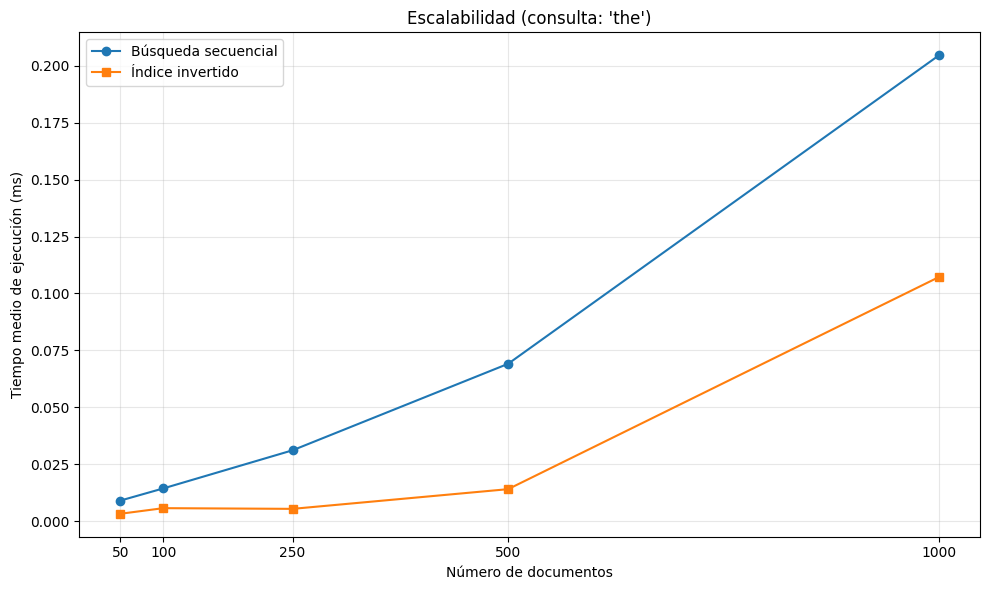

Tabla guardada en resultados_escalabilidad.csv


In [3]:
import gc
import time
import statistics
import pandas as pd
import matplotlib.pyplot as plt

TAMANOS = [50, 100, 250, 500, 1000]
REPETICIONES = 30
CONSULTA = "the"
TAMANOS_VALIDOS = sorted(set(min(n, len(archivos_unicos)) for n in TAMANOS if n > 0))
print("Consulta experimental:", CONSULTA)
print("Tamaños evaluados:", TAMANOS_VALIDOS)


def tiempo_promedio_busqueda(funcion, consulta, datos, repeticiones=30):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        funcion(consulta, datos)
        tiempos.append((time.perf_counter_ns() - inicio) / 1_000_000)
    return statistics.mean(tiempos)


resultados_escalabilidad = []
for n in TAMANOS_VALIDOS:
    documentos_tokenizados = {
        obtener_id_canonico(ref): tokenizar(leer_documento(ref))
        for ref in archivos_unicos[:n]
    }
    total_tokens = sum(len(tokens) for tokens in documentos_tokenizados.values())
    tiempo_secuencial = tiempo_promedio_busqueda(buscar_secuencial, CONSULTA,
                                                 documentos_tokenizados, REPETICIONES)
    secuencial = buscar_secuencial(CONSULTA, documentos_tokenizados)

    inicio = time.perf_counter_ns()
    indice_invertido = construir_indice_invertido(documentos_tokenizados)
    tiempo_construccion = (time.perf_counter_ns() - inicio) / 1_000_000
    tiempo_indice = tiempo_promedio_busqueda(buscar_con_indice, CONSULTA,
                                             indice_invertido, REPETICIONES)
    indexado = buscar_con_indice(CONSULTA, indice_invertido)
    iguales = secuencial == indexado
    resultados_escalabilidad.append({
        "Documentos": len(documentos_tokenizados), "Total de tokens": total_tokens,
        "Consulta": CONSULTA, "Repeticiones": REPETICIONES,
        "Tiempo secuencial (ms)": tiempo_secuencial,
        "Tiempo índice (ms)": tiempo_indice,
        "Construcción índice (ms)": tiempo_construccion,
        "Resultados iguales": iguales })
    print(f"n={n}: secuencial={tiempo_secuencial:.6f} ms, índice={tiempo_indice:.6f} ms")
    del documentos_tokenizados, indice_invertido
    gc.collect()

df_escalabilidad = pd.DataFrame(resultados_escalabilidad)
display(df_escalabilidad.round(6))
if not df_escalabilidad["Resultados iguales"].all():
    print("ADVERTENCIA: los resultados de ambos métodos no coinciden.")

plt.figure(figsize=(10, 6))
plt.plot(df_escalabilidad["Documentos"], df_escalabilidad["Tiempo secuencial (ms)"],
         marker="o", label="Búsqueda secuencial")
plt.plot(df_escalabilidad["Documentos"], df_escalabilidad["Tiempo índice (ms)"],
         marker="s", label="Índice invertido")
plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio de ejecución (ms)")
plt.title(f"Escalabilidad (consulta: {CONSULTA!r})")
plt.xticks(df_escalabilidad["Documentos"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
df_escalabilidad.to_csv("resultados_escalabilidad.csv", index=False, encoding="utf-8-sig")
print("Tabla guardada en resultados_escalabilidad.csv")


**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

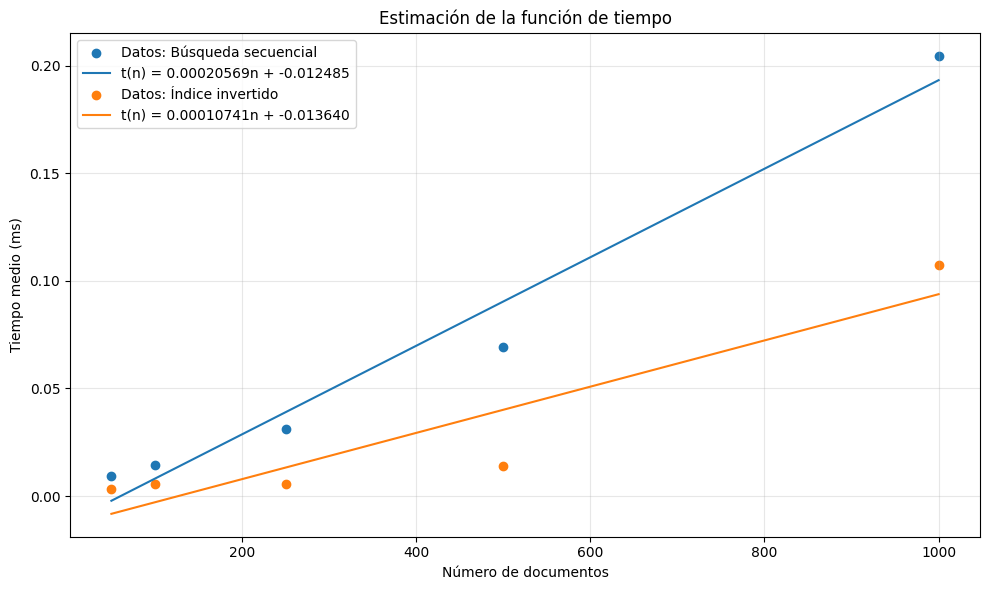

Funciones ajustadas:
Búsqueda secuencial: t(n) = 0.00020569n + -0.012485; R² = 0.969312
Índice invertido: t(n) = 0.00010741n + -0.013640; R² = 0.860896


In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
coeficientes = {}
for columna, etiqueta in [("Tiempo secuencial (ms)", "Búsqueda secuencial"),
                          ("Tiempo índice (ms)", "Índice invertido")]:
    n = df_escalabilidad["Documentos"].to_numpy(dtype=float)
    t = df_escalabilidad[columna].to_numpy(dtype=float)
    a, b = np.polyfit(n, t, 1)
    ajustado = a * n + b
    t_media = t.mean()
    r2 = 1 - ((t - ajustado)**2).sum() / ((t - t_media)**2).sum()
    coeficientes[etiqueta] = (a, b, r2)
    plt.scatter(n, t, label=f"Datos: {etiqueta}")
    plt.plot(n, ajustado, label=f"t(n) = {a:.8f}n + {b:.6f}")

plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio (ms)")
plt.title("Estimación de la función de tiempo")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Funciones ajustadas:")
for metodo, (a, b, r2) in coeficientes.items():
    print(f"{metodo}: t(n) = {a:.8f}n + {b:.6f}; R² = {r2:.6f}")
